# 3. Коллаборативная фильтрация: Item-based CF

Идея метода: книги похожи, если их одинаково оценивают одни и те же люди. Чтобы предсказать оценку пользователя
для книги, смотрим на его оценки похожих книг.

План:
1. матрица взаимодействий пользователь-книга в разреженном виде
2. матрица попарных сходств книг (косинусная близость по векторам оценок)
3. предсказание оценки по K наиболее похожим книгам и RMSE на тесте
4. top-N рекомендации
5. ответ на вопрос о вычислительной сложности

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import normalize

from utils import (
    N_BOOKS, N_USERS, SEED, TOP_K,
    get_eval_users, keep_top_k, load_books, load_ratings, recommend_top_k, save_recs, split_ratings, to_sparse,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

ratings = load_ratings()
books = load_books()
train, test = split_ratings(ratings)
eval_users = get_eval_users(test)

## Матрица взаимодействий

В строках пользователи, в столбцах книги, в ячейках явные оценки от 1 до 5 (ноль означает, что оценки нет).
Матрицу строим только по обучающей части.

In [2]:
R = to_sparse(train)

sparse_mb = (R.data.nbytes + R.indices.nbytes + R.indptr.nbytes) / 1e6
dense_mb = N_USERS * N_BOOKS * 4 / 1e6
print(repr(R))
print(f"Заполнено: {R.nnz / (N_USERS * N_BOOKS):.3%}")
print(f"Память: {sparse_mb:.1f} МБ в формате CSR против {dense_mb:.0f} МБ в плотном виде")

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 784517 stored elements and shape (53424, 10000)>
Заполнено: 0.147%
Память: 6.5 МБ в формате CSR против 2137 МБ в плотном виде


В плотном виде матрица заняла бы около 2 ГБ, а в CSR меньше 10 МБ, потому что хранятся только ненулевые элементы.

## Сходство книг

Каждая книга соответствует столбцу матрицы, то есть вектору оценок длиной в число пользователей.
Косинусная близость двух книг:

$$\text{sim}(i, j) = \frac{r_i \cdot r_j}{\lVert r_i \rVert \, \lVert r_j \rVert}$$

Если нормировать столбцы на единичную длину, вся матрица сходств получается одним умножением разреженных матриц: $S = X^T X$.

In [3]:
def cosine_item_similarity(R):
    """Косинусная близость между столбцами (книгами) разреженной матрицы оценок."""
    X = normalize(R.tocsc(), norm="l2", axis=0)
    sim = (X.T @ X).tocsr()
    sim.setdiag(0)  # сходство книги с самой собой не нужно
    sim.eliminate_zeros()
    return sim

In [4]:
%%time
sim = cosine_item_similarity(R)

CPU times: user 239 ms, sys: 11.2 ms, total: 250 ms
Wall time: 256 ms


In [5]:
print(f"Размер: {sim.shape}, ненулевых элементов: {sim.nnz:,} ({sim.nnz / N_BOOKS**2:.1%})")
print(f"Память: {(sim.data.nbytes + sim.indices.nbytes + sim.indptr.nbytes) / 1e6:.0f} МБ")
print(f"Медиана ненулевого сходства: {np.median(sim.data):.3f}, 99-й перцентиль: {np.quantile(sim.data, 0.99):.3f}")

Размер: (10000, 10000), ненулевых элементов: 18,296,300 (18.3%)
Память: 146 МБ


Медиана ненулевого сходства: 0.015, 99-й перцентиль: 0.142


Матрица сходств заполнена на 18%. У остальных пар книг нет ни одного общего читателя, и сходство равно нулю.
При этом большинство ненулевых значений очень маленькие, это пары с одним-двумя общими пользователями.

Посмотрим на ближайших соседей знакомой книги.

In [6]:
def similar_books_cf(book_id: int, n: int = 5) -> pd.DataFrame:
    row = sim[book_id - 1].toarray().ravel()
    top = np.argsort(-row)[:n]
    result = books.loc[top, ["book_id", "title", "authors"]].copy()
    result["similarity"] = row[top].round(3)
    return result.reset_index(drop=True)


print(books.loc[0, "title"])
similar_books_cf(1)

The Hunger Games (The Hunger Games, #1)


,book_id,title,authors,similarity
0,17,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,0.503
1,31,The Help,Kathryn Stockett,0.468
2,20,"Mockingjay (The Hunger Games, #3)",Suzanne Collins,0.435
3,37,"The Lion, the Witch, and the Wardrobe (Chronic...",C.S. Lewis,0.404
4,2,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",0.401


In [7]:
book_id = int(books.loc[books["title"] == "To Kill a Mockingbird", "book_id"].iloc[0])
print(books.loc[book_id - 1, "title"])
similar_books_cf(book_id)

To Kill a Mockingbird


,book_id,title,authors,similarity
0,8,The Catcher in the Rye,J.D. Salinger,0.552
1,13,1984,"George Orwell, Erich Fromm, Celâl Üster",0.509
2,5,The Great Gatsby,F. Scott Fitzgerald,0.477
3,32,Of Mice and Men,John Steinbeck,0.477
4,14,Animal Farm,George Orwell,0.471


Соседи получены только из оценок, без названий и тегов, но выглядят разумно. В отличие от контентной модели,
здесь близкими оказываются книги, которые читает одна и та же аудитория, даже если формально жанры разные.

## Предсказание оценки

Для пары (пользователь $u$, книга $i$) берём K книг, наиболее похожих на $i$ среди тех, что пользователь уже оценил,
и усредняем его оценки с весами-сходствами:

$$\hat r_{ui} = \frac{\sum_{j \in N_K(i, u)} \text{sim}(i, j) \, r_{uj}}{\sum_{j \in N_K(i, u)} \text{sim}(i, j)}$$

Если ни одна из оценённых пользователем книг не похожа на $i$ (все сходства нулевые), возвращаем среднюю оценку книги.

In [8]:
global_mean = train["rating"].mean()
book_means = np.full(N_BOOKS, global_mean)
mean_by_book = train.groupby("book_id")["rating"].mean()
book_means[mean_by_book.index - 1] = mean_by_book.values


def predict_rating(user_id: int, book_id: int, k: int = 20) -> float:
    """Оценка пользователя для книги по k наиболее похожим книгам из его истории."""
    user_row = R[user_id - 1]
    rated, user_ratings = user_row.indices, user_row.data
    sims = sim[book_id - 1, rated].toarray().ravel()

    top = np.argsort(-sims)[:k]
    top = top[sims[top] > 0]
    if len(top) == 0:
        return book_means[book_id - 1]
    return float(sims[top] @ user_ratings[top] / sims[top].sum())


example = test.iloc[0]
print(f"Пользователь {example.user_id}, книга: {books.loc[example.book_id - 1, 'title']}")
print(f"Настоящая оценка: {example.rating}, предсказанная: {predict_rating(example.user_id, example.book_id):.2f}")

Пользователь 1, книга: The Forty Rules of Love
Настоящая оценка: 4, предсказанная: 4.00


### Выбор K

Подберём число соседей по RMSE на случайной подвыборке теста из 20 000 оценок (на всём тесте перебор шёл бы дольше).

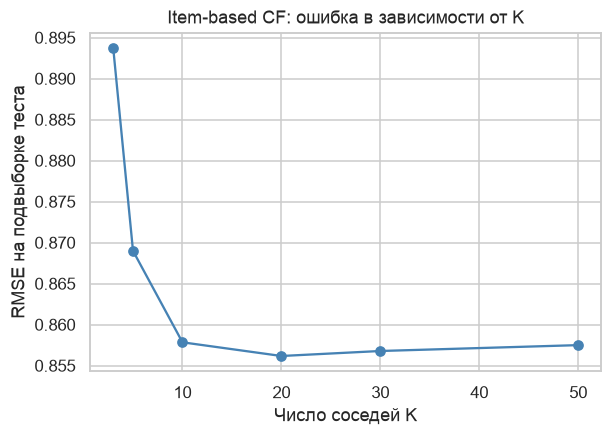

K,3,5,10,20,30,50
RMSE,0.8937,0.869,0.8578,0.8562,0.8568,0.8575


In [9]:
def rmse(y_true, y_pred) -> float:
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))


def predict_many(pairs: pd.DataFrame, k: int) -> np.ndarray:
    return np.array([predict_rating(u, b, k) for u, b in zip(pairs["user_id"], pairs["book_id"])])


test_sample = test.sample(20_000, random_state=SEED)
k_values = [3, 5, 10, 20, 30, 50]
rmse_by_k = [rmse(test_sample["rating"], predict_many(test_sample, k)) for k in k_values]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(k_values, rmse_by_k, marker="o", color="steelblue")
ax.set_xlabel("Число соседей K")
ax.set_ylabel("RMSE на подвыборке теста")
ax.set_title("Item-based CF: ошибка в зависимости от K")
plt.show()

pd.DataFrame({"K": k_values, "RMSE": np.round(rmse_by_k, 4)}).set_index("K").T

При маленьком K предсказание шумное, после K = 20 ошибка почти не меняется. Берём K = 20.
У половины пользователей оценок меньше десяти, так что для них в усреднение всё равно попадает вся история.

In [10]:
%%time
K_NEIGHBORS = 20

rmse_table = pd.DataFrame(
    {
        "RMSE на тесте": [
            rmse(test["rating"], np.full(len(test), global_mean)),
            rmse(test["rating"], book_means[test["book_id"] - 1]),
            rmse(test["rating"], predict_many(test, K_NEIGHBORS)),
        ]
    },
    index=["Глобальное среднее", "Средняя оценка книги", f"Item-based CF (K={K_NEIGHBORS})"],
).round(4)
rmse_table

CPU times: user 6.94 s, sys: 153 ms, total: 7.09 s
Wall time: 7.1 s


,RMSE на тесте
Глобальное среднее,0.9824
Средняя оценка книги,0.9458
Item-based CF (K=20),0.8519


Item-based CF заметно лучше обоих наивных бейзлайнов. С SVD сравним в следующем ноутбуке, тест там тот же.

## Top-N рекомендации

Для рекомендаций нужно оценить сразу все книги для пользователя. Чтобы не считать по одной паре,
оставим в матрице сходств только K ближайших соседей каждой книги и перемножим матрицы:

$$\text{score}(u, i) = \sum_{j \in N_K(i)} \text{sim}(i, j) \, r_{uj}$$

Это числитель формулы предсказания оценки, без деления на сумму сходств. Для ранжирования так лучше.
Средневзвешенная оценка равна 5.0 у любой книги, у которой единственный сосед в истории пользователя получил пятёрку,
даже если сходство с ним почти нулевое. Сумма учитывает и то, насколько книга похожа на прочитанное,
и то, сколько похожих книг набралось в истории. Для сравнения посчитаем оба варианта, метрики будут в ноутбуке 5.

In [11]:
sim_top = keep_top_k(sim, K_NEIGHBORS)
sim_top_t = sim_top.T.tocsr()
has_rating = (R > 0).astype(np.float32)

print(f"В матрице сходств осталось {sim_top.nnz:,} значений из {sim.nnz:,}")


def item_cf_scores(user_idx):
    return (R[user_idx] @ sim_top_t).toarray()


def item_cf_weighted_mean_scores(user_idx):
    numerator = (R[user_idx] @ sim_top_t).toarray()
    denominator = (has_rating[user_idx] @ sim_top_t).toarray()
    return np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0)

В матрице сходств осталось 200,000 значений из 18,296,300


In [12]:
%%time
recs_item_cf = recommend_top_k(item_cf_scores, seen=R, user_ids=eval_users, k=TOP_K)
recs_item_cf_wmean = recommend_top_k(item_cf_weighted_mean_scores, seen=R, user_ids=eval_users, k=TOP_K)

save_recs("item_cf", eval_users, recs_item_cf)
save_recs("item_cf_wmean", eval_users, recs_item_cf_wmean)

CPU times: user 1.98 s, sys: 74.9 ms, total: 2.05 s
Wall time: 2.07 s


In [13]:
def recommend_item_cf(user_id: int, N: int = 5) -> pd.DataFrame:
    """Top-N книг для пользователя по Item-based CF."""
    recs = recommend_top_k(item_cf_scores, seen=R, user_ids=[user_id], k=N)[0]
    return books.set_index("book_id").loc[recs, ["title", "authors"]].reset_index()


user_id = int(train.groupby("user_id").size().loc[lambda s: s == 15].index[0])
history = train[train["user_id"] == user_id].merge(books[["book_id", "title"]], on="book_id")
print(f"Пользователь {user_id}, оценённые книги:")
print(history.sort_values("rating", ascending=False)[["rating", "title"]].to_string(index=False))

recommend_item_cf(user_id, N=7)

Пользователь 22, оценённые книги:
 rating                                                     title
      5        The Long Walk: The True Story of a Trek to Freedom
      4       The Walking Dead, Book One (The Walking Dead #1-12)
      4 Gates of Fire: An Epic Novel of the Battle of Thermopylae
      4          Day by Day Armageddon (Day by Day Armageddon,#1)
      4           The Dragon's Path (The Dagger and the Coin, #1)
      4    The Walking Dead, Book Three (The Walking Dead #25-36)
      4         Sin City, Vol. 3: The Big Fat Kill (Sin City, #3)
      3                           Empire of Ivory (Temeraire, #4)
      3           The Short Victorious War (Honor Harrington, #3)
      3                                            The Algebraist
      3               Black Sun Rising (The Coldfire Trilogy, #1)
      3                  Field of Dishonor (Honor Harrington, #4)
      3                Honor Among Enemies (Honor Harrington, #6)
      3                      Flag in Exile

,book_id,title,authors
0,6013,"The Honor of the Queen (Honor Harrington, #2)",David Weber
1,8078,"The Walking Dead, Book Two (The Walking Dead #...","Robert Kirkman, Charlie Adlard"
2,3644,"On Basilisk Station (Honor Harrington, #1)",David Weber
3,8135,"Fearless (The Lost Fleet, #2)",Jack Campbell
4,9581,"Courageous (The Lost Fleet, #3)",Jack Campbell
5,6371,"Black Powder War (Temeraire, #3)",Naomi Novik
6,8988,"Victory of Eagles (Temeraire, #5)",Naomi Novik


## Вычислительная сложность и оптимизация

Пусть в данных $m$ пользователей, $n$ книг и $\text{nnz}$ оценок.

### Построение матрицы сходств

- Наивный способ: для каждой из $n^2 / 2$ пар книг сравнить два вектора длины $m$, по времени это $O(n^2 m)$.
  Для наших данных получается $10^4 \cdot 10^4 \cdot 5 \cdot 10^4 / 2 \approx 2.5 \cdot 10^{12}$ операций.
- С разреженными матрицами считаются только пары книг, у которых есть общий пользователь. Каждый пользователь
  с $k_u$ оценками даёт вклад в $k_u^2$ пар, поэтому время равно $O(\sum_u k_u^2)$. Здесь это доли секунды.
  Но сумма квадратов быстро растёт, её определяют самые активные пользователи.
- По памяти это $O(n^2)$ в худшем случае. У нас 18 млн ненулевых значений (18% матрицы) на 10 тысяч книг.
  При миллионе товаров полная матрица уже не поместится ни в память, ни на диск.

### Предсказание

Одна оценка считается за $O(k_u \log k_u)$: надо взять сходства с книгами пользователя и отсортировать.
Top-N для одного пользователя по усечённой матрице считается за $O(k_u K + n)$, то есть линейно по каталогу.

### Обновление

Сходства зависят от всех оценок, поэтому при появлении новых данных матрицу приходится пересчитывать.
Обычно это делают офлайн раз в сутки. Сходства книг меняются медленно, и в этом преимущество item-based подхода
перед user-based.

### Как оптимизировать для больших данных

1. Хранить всё в разреженном виде и считать сходства матричным умножением (как сделано здесь), а не циклом по парам.
2. Оставлять для каждой книги только top-K соседей, тогда память падает с $O(n^2)$ до $O(nK)$. У нас это 200 тысяч значений вместо 18 млн.
3. Не учитывать пары с малым числом общих пользователей или штрафовать их (shrinkage). Так меньше шума и меньше ненулевых значений.
4. Ограничивать историю самых активных пользователей (сэмплировать их оценки), чтобы убрать квадратичный вклад $k_u^2$.
5. Искать соседей приближённо через LSH/MinHash или ANN-индексы (Faiss, HNSW) по векторам книг вместо точного перебора всех пар.
6. Сжимать векторы книг. Вместо столбца длины $m$ использовать эмбеддинг из матричного разложения (следующий ноутбук)
   и считать близость в пространстве размерности 50-100.
7. Считать распределённо (Spark, MapReduce), задача хорошо параллелится по пользователям или по блокам столбцов.